# Introduction

In part 1 of this assessment, you will complete several requested SQL queries in order to extract data, analyze, and provide insights from a single provided SQL database. You will also visualize the key results of 3 of these queries. There are also several 'Reflection' questions that ask you to write out a text based answer in the provided markdown cell. Following the guided question and answer section, in part 2 you will explore a second dataset on your own using SQL in order to conduct a preliminary analysis. You will be asked to produce a very short slide presentation highlighting the work you did for this second section.

## Objectives
You will be able to:
- Interpret "word problems" and translate them into SQL queries
- Decide and perform whichever type of JOIN is best for retrieving desired data
- Use GROUP BY statements to apply aggregate functions like COUNT, MAX, MIN, and SUM
- Use the HAVING clause to compare different aggregates
- Write subqueries to decompose complex queries
- Visualize data using matplotlib, seaborn, or pandas
- Choose the correct chart type based on the given data


## Part 1: Guided SQL Queries

### Your Task: Querying a Customer Database

![toy car picture](images/toycars.jpg)


### Business Understanding
Your employer sells wholesale miniature models of products such as classic cars, motorcycles, and planes. They want you to pull several reports on different segments of their past customers, in order to better understand past sales as well as determine which customers will receive promotional material. They are also interested in investigating which products have performed the best, as well as having several smaller asks.

In addition to providing the requested data from the SQL database you have also been asked to create some basic visuals to display some of the more insightful information. It is up to your discretion to choose the correct plot/chart type for the data in question. **Questions that want you to visualize the results will be explicitly marked**.

### Data Understanding
You may remember this database from a previous lab. As a refresher, here's the ERD diagram for this database:

![ERD picture](images/ERD.png)

The queries you are asked to write will become more complex over the course of the lab.



### Getting Started
For this assessment you are expected to make use of both sqlite3 and the Pandas libraries in order to write, execute, and return SQL queries as a Pandas DataFrame. Assign each returned answer as its own explicit variable.

For the visualization piece you are expected to utilize either Pandas, Seaborn, or Matplotlib to create your visuals. Make sure you are providing verbose labels and titles according to the data you are being asked to visualize. Do not worry too much about choosing a 'style' or 'context' instead focus on conveying the requested information correctly.

### Step 1: Connect to Data

In the cell below
- Import the necessary libraries
- Establish a connection to the database data.sqlite

In [1]:
# Imports
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

# Create connection to database
conn = sqlite3.connect('data.sqlite')

### Step 2: Limited Edition California Product
The California sales rep team is interested in running promotional material for a new limited edition model they are releasing based on the famous San Francisco Cable Cars. This product will only be available to customer stores based in California and given its high price value they want to first target promotional material to existing California customers with a high credit limit. Upon communicating with the accounting department, a credit limit of over 25,000 is considered to be high. 

Execute a SQl query that returns which customers the sales rep team wants to market to first.
*Hint*: Make sure creditLimit is numeric.

In [2]:
# creditLimit is stored as TEXT in this database, so CAST it to a number before comparing
california_high_credit_df = pd.read_sql("""
SELECT customerNumber,
       customerName,
       contactFirstName,
       contactLastName,
       phone,
       city,
       state,
       CAST(creditLimit AS REAL) AS creditLimit
FROM customers
WHERE state = 'CA'
  AND country = 'USA'
  AND CAST(creditLimit AS REAL) > 25000
ORDER BY creditLimit DESC;
""", conn)

california_high_credit_df

,customerNumber,customerName,contactFirstName,contactLastName,phone,city,state,creditLimit
0,124,Mini Gifts Distributors Ltd.,Susan,Nelson,4155551450,San Rafael,CA,210500.0
1,239,Collectable Mini Designs Co.,Valarie,Thompson,7605558146,San Diego,CA,105000.0
2,321,Corporate Gift Ideas Co.,Julie,Brown,6505551386,San Francisco,CA,105000.0
3,205,Toys4GrownUps.com,Julie,Young,6265557265,Pasadena,CA,90700.0
4,161,Technics Stores Inc.,Juri,Hashimoto,6505556809,Burlingame,CA,84600.0
5,450,The Sharp Gifts Warehouse,Sue,Frick,4085553659,San Jose,CA,77600.0
6,129,Mini Wheels Co.,Julie,Murphy,6505555787,San Francisco,CA,64600.0
7,487,Signal Collectibles Ltd.,Sue,Taylor,4155554312,Brisbane,CA,60300.0
8,347,"Men 'R' US Retailers, Ltd.",Brian,Chandler,2155554369,Los Angeles,CA,57700.0
9,475,West Coast Collectables Co.,Steve,Thompson,3105553722,Burbank,CA,55400.0


### Step 3: International Collectable Campaign

The international sales rep team has reached out to you to help them identify partners for a 'Collectable' marketing campaign that highlights the potential collectors value in purchasing these model kits. They want to try and promote a 'collect them all' mentality. The team had a great idea to partner with any of their international customers (non-US) who have "Collect" in their name as a tie in to the larger theme.

Execute a SQL that returns the customers in question.

In [3]:
international_collect_df = pd.read_sql("""
SELECT customerNumber,
       customerName,
       contactFirstName,
       contactLastName,
       city,
       country
FROM customers
WHERE country <> 'USA'
  AND customerName LIKE '%Collect%'
ORDER BY country, customerName;
""", conn)

international_collect_df

,customerNumber,customerName,contactFirstName,contactLastName,city,country
0,471,"Australian Collectables, Ltd",Sean,Clenahan,Glen Waverly,Australia
1,114,"Australian Collectors, Co.",Peter,Ferguson,Melbourne,Australia
2,382,Salzburg Collectables,Georg,Pipps,Salzburg,Austria
3,260,"Royal Canadian Collectables, Ltd.",Elizabeth,Lincoln,Tsawassen,Canada
4,227,Heintze Collectables,Palle,Ibsen,Århus,Denmark
5,353,Reims Collectables,Paul,Henriot,Reims,France
6,415,"Bavarian Collectables Imports, Co.",Michael,Donnermeyer,Munich,Germany
7,409,Stuttgart Collectable Exchange,Rita,Müller,Stuttgart,Germany
8,211,"King Kong Collectables, Co.",Mike,Gao,Central Hong Kong,Hong Kong
9,189,"Clover Collections, Co.",Dean,Cassidy,Dublin,Ireland


## Reflection Question:

Describe the WHERE clause you used in the above query to a non-technical manager who wants to be ensured that you are properly filtering and only selecting the requested data. How is the operator and conditional expression you are using acting to accomplish this?

The WHERE clause has two conditions joined with **AND**, which means a customer is only returned if **both** are true:

1. `country <> 'USA'` - the `<>` operator means "is not equal to". Any customer whose country is the USA is removed, which leaves only international customers.
2. `customerName LIKE '%Collect%'` - `LIKE` is a pattern match instead of an exact match. The `%` symbol is a wildcard meaning "any characters, including none", so `%Collect%` means "the name contains the letters *Collect* anywhere". This catches *Collectables*, *Collectors*, *Collections* and *Collectibles*. (SQLite's `LIKE` ignores upper/lower case, so it would also catch "collect".)

Because of the AND, a US customer named "Tekni Collectables Inc." is excluded (fails condition 1), and an international customer such as "Atelier graphique" is excluded (fails condition 2). Only international customers with "Collect" in their name remain.

### Step 4: USA Credit and Inventory Policy - Visual Required
The USA based product team is planning to adjust its credit policies and inventory allocation strategy based on the average credit limit of its customers. They would like to target this strategy at a state level with several goals in mind. 
1. Optimize inventory distribution:
    - States with higher average credit limits might be able to place larger orders, justifying priority in inventory allocation.
    - This could help ensure that states with more purchasing power always have products in stock.
2. Tailor credit policies:
    - Adjust credit limits for new customers based on the state average.
    - Identify states where they might be too conservative or too liberal with credit limits.
3. Target marketing and sales efforts:
    - Focus promotional campaigns on states with higher credit limits, potentially leading to larger orders.
    - Develop strategies to increase sales in states with lower average credit limits.

Execute a SQl query that returns the information required to address this ask.

In [4]:
usa_credit_by_state_df = pd.read_sql("""
SELECT state,
       COUNT(*) AS num_customers,
       ROUND(AVG(CAST(creditLimit AS REAL)), 2) AS avg_credit_limit
FROM customers
WHERE country = 'USA'
GROUP BY state
ORDER BY avg_credit_limit DESC;
""", conn)

usa_credit_by_state_df

,state,num_customers,avg_credit_limit
0,NH,1,114200.00
1,NY,6,89966.67
2,PA,3,84766.67
3,CA,11,83854.55
4,NV,1,71800.00
5,MA,9,70755.56
6,CT,4,57350.00
7,NJ,1,43000.00


Once you have the information returned in a dataframe, select an appropriate visualization to represent this data. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

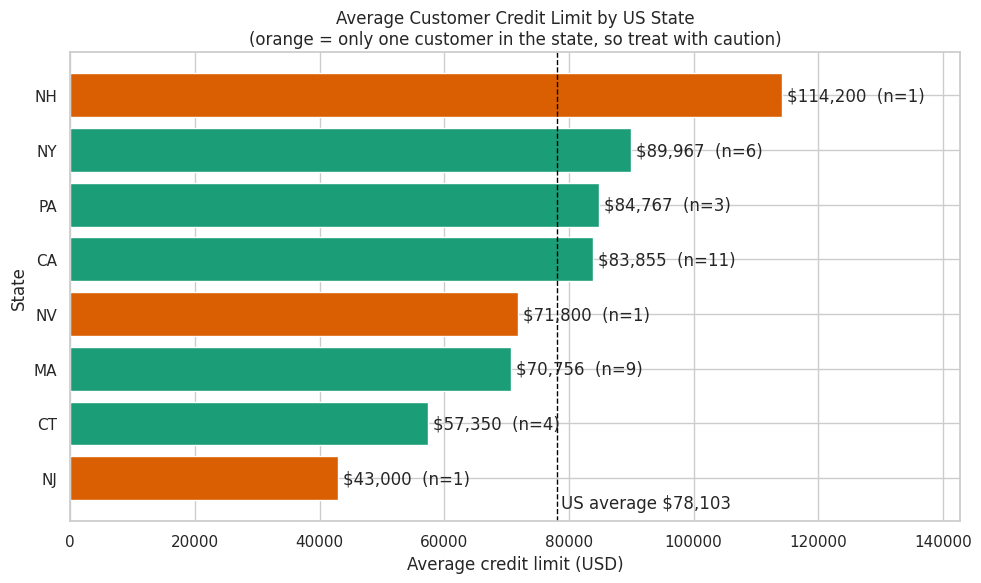

In [5]:
# Produce a visual to represent the average credit limit by state
plot_df = usa_credit_by_state_df.sort_values('avg_credit_limit')
overall_avg = pd.read_sql("SELECT AVG(CAST(creditLimit AS REAL)) AS a FROM customers WHERE country = 'USA'", conn)['a'][0]

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(plot_df['state'], plot_df['avg_credit_limit'],
               color=['#d95f02' if n == 1 else '#1b9e77' for n in plot_df['num_customers']])
for bar, n, v in zip(bars, plot_df['num_customers'], plot_df['avg_credit_limit']):
    ax.text(v + 800, bar.get_y() + bar.get_height() / 2, f"${v:,.0f}  (n={n})", va='center')
ax.axvline(overall_avg, color='black', linestyle='--', linewidth=1)
ax.text(overall_avg + 600, -0.45, f"US average ${overall_avg:,.0f}", ha="left", va="center")
ax.set_xlim(0, plot_df['avg_credit_limit'].max() * 1.25)
ax.set_title('Average Customer Credit Limit by US State\n(orange = only one customer in the state, so treat with caution)')
ax.set_xlabel('Average credit limit (USD)')
ax.set_ylabel('State')
plt.tight_layout()
plt.show()

### Step 5: Top Customers - Visual Required
The company is approaching its 10 year anniversary and wants to acknowledge and thank its top customers with personalized communication. They have asked you to determine the top 10 customers based on the total amount of payments made, making sure to return the customer name for clarity. 

Execute a SQl query that returns the information required to address this ask.


In [6]:
top_customers_df = pd.read_sql("""
SELECT c.customerNumber,
       c.customerName,
       ROUND(SUM(CAST(p.amount AS REAL)), 2) AS total_payments
FROM customers AS c
JOIN payments AS p
  ON c.customerNumber = p.customerNumber
GROUP BY c.customerNumber, c.customerName
ORDER BY total_payments DESC
LIMIT 10;
""", conn)

top_customers_df

,customerNumber,customerName,total_payments
0,141,Euro+ Shopping Channel,715738.98
1,124,Mini Gifts Distributors Ltd.,584188.24
2,114,"Australian Collectors, Co.",180585.07
3,151,Muscle Machine Inc,177913.95
4,148,"Dragon Souveniers, Ltd.",156251.03
5,323,"Down Under Souveniers, Inc",154622.08
6,187,"AV Stores, Co.",148410.09
7,276,"Anna's Decorations, Ltd",137034.22
8,321,Corporate Gift Ideas Co.,132340.78
9,146,"Saveley & Henriot, Co.",130305.35


Once you have the information returned in a dataframe, select an appropriate visualization to represent this data. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

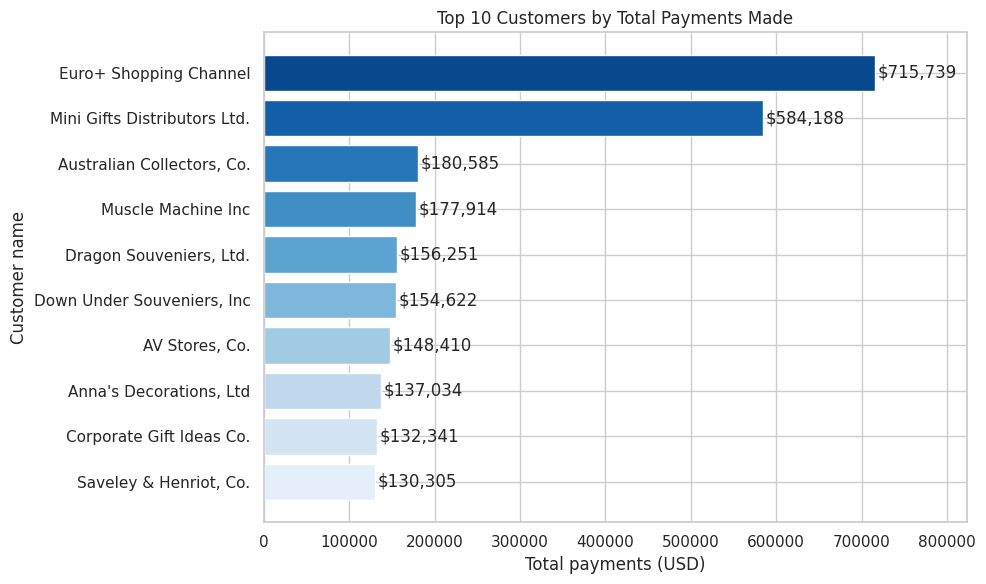

In [7]:
# Produce a visual to represent the top ten customers in terms of total payments
plot_df = top_customers_df.sort_values('total_payments')

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(plot_df['customerName'], plot_df['total_payments'], color=sns.color_palette('Blues', len(plot_df)))
for bar, v in zip(bars, plot_df['total_payments']):
    ax.text(v + 3000, bar.get_y() + bar.get_height() / 2, f"${v:,.0f}", va='center')
ax.set_xlim(0, plot_df['total_payments'].max() * 1.15)
ax.set_title('Top 10 Customers by Total Payments Made')
ax.set_xlabel('Total payments (USD)')
ax.set_ylabel('Customer name')
plt.tight_layout()
plt.show()

### Step 6: Top Customer + Product Quantities
The product team is running an analysis on popular and common products sold to each customer in order to try and determine what new products they should be looking at to include in their catalog. This data will also be used by individual sales reps to recommend similar products to each customer next time they place an order. 

They have asked you to query information, for each customer, about any product they have purchased 10 or more units of. In addition they would like the full set of data to be sorted in ascending order by the total amount purchased.

Execute a SQl query that returns the information required to address this ask.

Hint: For this one, you'll need to make use of HAVING, GROUP BY, and ORDER BY — make sure you get the order of them correct!

In [8]:
customer_product_qty_df = pd.read_sql("""
SELECT c.customerNumber,
       c.customerName,
       p.productCode,
       p.productName,
       SUM(CAST(od.quantityOrdered AS INTEGER)) AS total_units_ordered,
       ROUND(SUM(CAST(od.quantityOrdered AS INTEGER) * CAST(od.priceEach AS REAL)), 2) AS total_spent
FROM customers AS c
JOIN orders AS o
  ON c.customerNumber = o.customerNumber
JOIN orderdetails AS od
  ON o.orderNumber = od.orderNumber
JOIN products AS p
  ON od.productCode = p.productCode
GROUP BY c.customerNumber, c.customerName, p.productCode, p.productName
HAVING SUM(CAST(od.quantityOrdered AS INTEGER)) >= 10
ORDER BY total_units_ordered ASC;
""", conn)

print(customer_product_qty_df.shape)
customer_product_qty_df.head(10)

(2531, 6)


,customerNumber,customerName,productCode,productName,total_units_ordered,total_spent
0,314,Petit Auto,S18_2949,1913 Ford Model T Speedster,10,891.50
1,412,"Extreme Desk Decorations, Ltd",S24_4620,1961 Chevrolet Impala,10,662.90
2,119,La Rochelle Gifts,S32_2509,1954 Greyhound Scenicruiser,11,553.52
3,328,Tekni Collectables Inc.,S700_1691,American Airlines: B767-300,11,854.04
4,450,The Sharp Gifts Warehouse,S24_3191,1969 Chevrolet Camaro Z28,13,1001.65
5,282,Souveniers And Things Co.,S24_3969,1936 Mercedes Benz 500k Roadster,15,529.35
6,382,Salzburg Collectables,S24_2972,1982 Lamborghini Diablo,15,481.50
7,386,L'ordine Souveniers,S18_2581,P-51-D Mustang,15,1064.40
8,398,"Tokyo Collectables, Ltd",S24_3969,1936 Mercedes Benz 500k Roadster,15,615.45
9,412,"Extreme Desk Decorations, Ltd",S18_3278,1969 Dodge Super Bee,16,1132.16


### Step 7: Product Analysis - Visual Required

The product team is looking into the demand across its different product lines. They are conducting a comprehensive review of its product portfolio and inventory management strategies. You have been asked to query data pertaining to each different product line, that contains the total quantity ordered and the total number of products for each respective product line. By examining the number of products and total quantity ordered for each product line, the company aims to:
1. Optimize product mix:
    - Identify which product lines have the most diverse offerings (high number of products)
    - Determine which lines are most popular (high total quantity ordered)
    - Compare if lines with more products necessarily lead to more orders
2. Improve inventory management:
    - Adjust stock levels based on the popularity of each product line
    - Identify potential overstocking in lines with low order quantities
    - Ensure adequate variety in high-performing product lines
3. Adjust marketing strategy:
    - Focus promotional efforts on product lines with high potential (many products but lower order quantities)
    - Capitalize on the popularity of high-performing lines in marketing campaigns
4. Advise Product development:
    - Invest in expanding product ranges for lines with high order quantities
    - Consider phasing out or revamping product lines with low numbers of products and low order quantities

Hint: Think about how you can and might have to utilize SQL DISTINCT statement

Execute a SQl query that returns the information required to address this ask.

In [9]:
# COUNT(DISTINCT productCode) is needed because joining products to orderdetails repeats each
# product once per order line; a plain COUNT would count products many times over.
product_line_df = pd.read_sql("""
SELECT p.productLine,
       COUNT(DISTINCT p.productCode) AS number_of_products,
       SUM(CAST(od.quantityOrdered AS INTEGER)) AS total_quantity_ordered
FROM products AS p
JOIN orderdetails AS od
  ON p.productCode = od.productCode
GROUP BY p.productLine
ORDER BY total_quantity_ordered DESC;
""", conn)

product_line_df

,productLine,number_of_products,total_quantity_ordered
0,Classic Cars,37,35582
1,Vintage Cars,24,22933
2,Motorcycles,13,12778
3,Planes,12,11872
4,Trucks and Buses,11,11001
5,Ships,9,8532
6,Trains,3,2818


Once you have the information returned in a dataframe, select an appropriate visualization to represent the relationship between total quantity ordered and the number of products in order to perform a preliminary investigation into the question of if more products lead to more orders. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

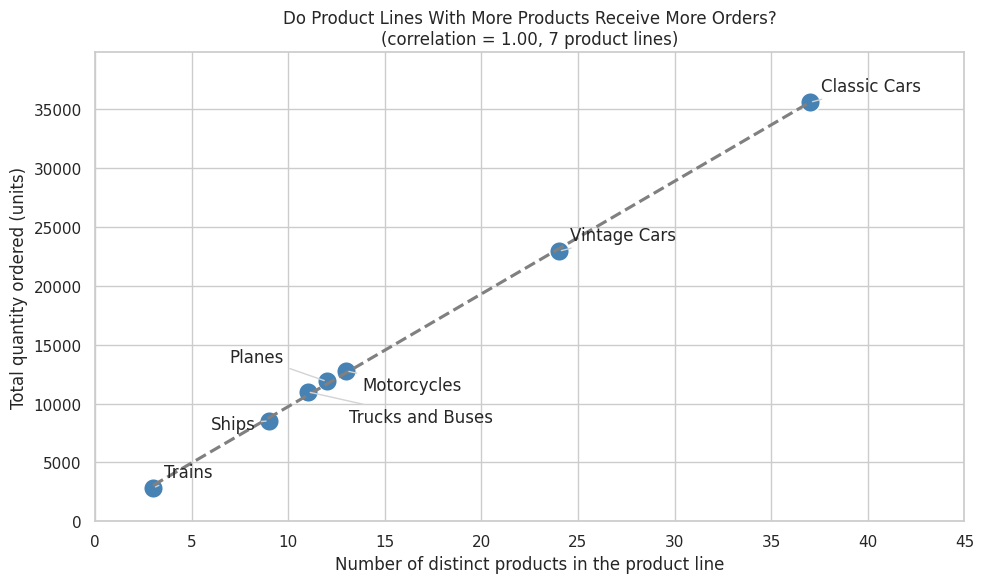

In [10]:
# Produce a visual to represent the the relation between number of products and the total amount ordered
fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=product_line_df, x='number_of_products', y='total_quantity_ordered',
                s=200, color='steelblue', ax=ax)
sns.regplot(data=product_line_df, x='number_of_products', y='total_quantity_ordered',
            scatter=False, ci=None, color='gray', line_kws={'linestyle': '--'}, ax=ax)
offsets = {'Motorcycles': (12, -14), 'Planes': (-70, 14), 'Trucks and Buses': (30, -22), 'Ships': (-42, -6)}
for _, r in product_line_df.iterrows():
    ax.annotate(r['productLine'], (r['number_of_products'], r['total_quantity_ordered']),
                xytext=offsets.get(r['productLine'], (8, 8)), textcoords='offset points',
                arrowprops=dict(arrowstyle='-', color='lightgray'))
corr = product_line_df['number_of_products'].corr(product_line_df['total_quantity_ordered'])
ax.set_title(f'Do Product Lines With More Products Receive More Orders?\n(correlation = {corr:.2f}, 7 product lines)')
ax.set_xlabel('Number of distinct products in the product line')
ax.set_ylabel('Total quantity ordered (units)')
ax.set_xlim(0, product_line_df['number_of_products'].max() + 8)
ax.set_ylim(0, product_line_df['total_quantity_ordered'].max() * 1.12)
plt.tight_layout()
plt.show()

## Reflection Question:

Please explain your choice in the type of visual you used in order to highlight and represent the data from the above query. In a non-technical manner explain why that chart type makes sense for the information being conveyed. What does this visual convey in the context of the question it was asked for?

I used a **scatter plot** because the question is "do product lines with more products get more orders?", which is about the *relationship between two numbers*. Each dot is one product line: how far right it sits is how many products it has, and how high it sits is how many units customers ordered. A bar chart would show each number separately but make it hard to see how they move together; a scatter plot lets you see at a glance whether dots climb from bottom-left to top-right. I added a dashed trend line and labelled each dot so you can tell which product line is which.

What it shows: the dots line up almost perfectly along the trend line (correlation of about 1.0). Lines with a larger catalogue (Classic Cars with 37 products, Vintage Cars with 24) also have the highest order volumes, while small lines (Trains with 3 products, Ships with 9) have the lowest. In fact every line sells roughly 940-1,000 units per product, so in this data the size of the catalogue goes almost hand in hand with total orders. Caution: there are only 7 product lines, and the chart cannot tell us whether extra variety *causes* more orders or whether popular lines were simply given more products. Because no line sits far below the trend, this view does not point to an obvious over-stocked line; a per-product comparison would be the next step.

### Step 8: Remote Offices
Upper management is considering a shift to hybrid and remote work for certain locations and roles. They have tasked you with providing them data about employees who work in any office that has fewer than 5 total employees so they can better understand how to support those employees remotely when offices are shut down. 

Be sure to include information about the employees job and supervisor so management can adjust everyone to remote work properly.

Hint: Utilize a subquery to find the relevant offices

Execute a SQl query that returns the information required to address this ask.

In [11]:
remote_office_employees_df = pd.read_sql("""
SELECT e.employeeNumber,
       e.firstName,
       e.lastName,
       e.jobTitle,
       e.email,
       e.officeCode,
       o.city AS office_city,
       o.country AS office_country,
       e.reportsTo AS supervisor_employee_number,
       s.firstName || ' ' || s.lastName AS supervisor_name,
       s.jobTitle AS supervisor_job_title
FROM employees AS e
JOIN offices AS o
  ON e.officeCode = o.officeCode
LEFT JOIN employees AS s
  ON e.reportsTo = s.employeeNumber
WHERE e.officeCode IN (
    SELECT officeCode
    FROM employees
    GROUP BY officeCode
    HAVING COUNT(*) < 5
)
ORDER BY e.officeCode, e.lastName;
""", conn)

remote_office_employees_df

,employeeNumber,firstName,lastName,jobTitle,email,officeCode,office_city,office_country,supervisor_employee_number,supervisor_name,supervisor_job_title
0,1188,Julie,Firrelli,Sales Rep,jfirrelli@classicmodelcars.com,2,Boston,USA,1143,Anthony Bow,Sales Manager (NA)
1,1216,Steve,Patterson,Sales Rep,spatterson@classicmodelcars.com,2,Boston,USA,1143,Anthony Bow,Sales Manager (NA)
2,1286,Foon Yue,Tseng,Sales Rep,ftseng@classicmodelcars.com,3,NYC,USA,1143,Anthony Bow,Sales Manager (NA)
3,1323,George,Vanauf,Sales Rep,gvanauf@classicmodelcars.com,3,NYC,USA,1143,Anthony Bow,Sales Manager (NA)
4,1625,Yoshimi,Kato,Sales Rep,ykato@classicmodelcars.com,5,Tokyo,Japan,1621,Mami Nishi,Sales Rep
5,1621,Mami,Nishi,Sales Rep,mnishi@classicmodelcars.com,5,Tokyo,Japan,1056,Mary Patterson,VP Sales
6,1611,Andy,Fixter,Sales Rep,afixter@classicmodelcars.com,6,Sydney,Australia,1088,William Patterson,Sales Manager (APAC)
7,1619,Tom,King,Sales Rep,tking@classicmodelcars.com,6,Sydney,Australia,1088,William Patterson,Sales Manager (APAC)
8,1612,Peter,Marsh,Sales Rep,pmarsh@classicmodelcars.com,6,Sydney,Australia,1088,William Patterson,Sales Manager (APAC)
9,1088,William,Patterson,Sales Manager (APAC),wpatterson@classicmodelcars.com,6,Sydney,Australia,1056,Mary Patterson,VP Sales


## Reflection Question:

Describe how you decided on the subquery that you used in the query above? This answer can be technically in nature, describing your thought process in how the main query is utilizing the subquery to return the correct data.

The question was about employees in offices with **fewer than 5 employees**, but each employee row does not know how big its own office is. So I split the problem in two:

1. **Subquery (finds the small offices):** `SELECT officeCode FROM employees GROUP BY officeCode HAVING COUNT(*) < 5`. It groups employees by office, counts them, and `HAVING` keeps only office codes whose count is under 5. I used `HAVING` instead of `WHERE` because the condition is on an aggregate (the count), and `WHERE` cannot filter on aggregates. The result is a short list of office codes (2, 3, 5, 6, 7).
2. **Main query (gets the people):** `WHERE e.officeCode IN (subquery)` keeps only employees whose office code is in that list. This avoids hard-coding office numbers, so the query stays correct if headcount changes.

To give management what they need for the transition, the main query also joins `offices` for the city/country and **self-joins** `employees` (as `s`) on `reportsTo = employeeNumber` to show each person's supervisor. A `LEFT JOIN` is used so no one is dropped if they have no supervisor listed.

### Step 9: Close the Connection

Now that you are finished executing your queries and retrieving the required information you always want to make sure to close the connection to your database.

In [12]:
# Close the connection to data.sqlite
conn.close()

### End of Guided Section
In this initial portion of the assessment, you produced several data queries and visualizations for a model company, mainly focused around its customer and product data. You wrote and engineered specific SQL queries to address pertinent questions and asks from the company. Along the way, you utilized many of the major concepts and keywords associated with SQL SELECT queries: FROM, WHERE, GROUP BY, HAVING, ORDER BY, JOIN, SUM, COUNT, and AVG.

## Part 2: Exploratory Analysis with SQL
In this open-ended exploratory section, you will analyze real-world data from the movie industry. As a data analyst, you have the freedom to investigate questions and topics that intrigue you within this dataset. The database schema and Entity-Relationship Diagram (ERD) are provided below for your reference. A general overview and instructions are also provided below.

In [13]:
# Run this cell without changes
import zipfile

zip_file_path = 'im.db.zip'
extract_to_path = './'

with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
    zip_ref.extractall(extract_to_path)

# Connection
conn4 = sqlite3.connect('im.db')

# Schema
schema_df = pd.read_sql("""
SElECT * FROM sqlite_master                        
""", conn4)
schema_df

,type,name,tbl_name,rootpage,sql
0,table,movie_basics,movie_basics,2,"CREATE TABLE ""movie_basics"" (\n""movie_id"" TEXT..."
1,table,directors,directors,3,"CREATE TABLE ""directors"" (\n""movie_id"" TEXT,\n..."
2,table,known_for,known_for,4,"CREATE TABLE ""known_for"" (\n""person_id"" TEXT,\..."
3,table,movie_akas,movie_akas,5,"CREATE TABLE ""movie_akas"" (\n""movie_id"" TEXT,\..."
4,table,movie_ratings,movie_ratings,6,"CREATE TABLE ""movie_ratings"" (\n""movie_id"" TEX..."
5,table,persons,persons,7,"CREATE TABLE ""persons"" (\n""person_id"" TEXT,\n ..."
6,table,principals,principals,8,"CREATE TABLE ""principals"" (\n""movie_id"" TEXT,\..."
7,table,writers,writers,9,"CREATE TABLE ""writers"" (\n""movie_id"" TEXT,\n ..."


## The Data

![movie ERD](images/movie_data_erd.jpeg)
### Database Content:

- Source: IMDB
- Time Range: Movies released between 2010 and 2019
- Note: Exclude any movies with a start_year after 2019 as this data is not current or accurate

Available Data Categories:
- Genre
- Runtime
- Personnel (writers, directors, actors)
- Movie ratings

### Objectives:

Initial Exploration:
- Use SQL in combination with Pandas to explore the database
- Identify interesting trends, patterns, or relationships in the data

Business Question Formulation:
- Develop at least one substantial business question for deeper analysis
- Ensure the question is relevant, specific, and can be addressed with the available data

Data Cleaning Assessment:
- Identify potential data cleaning tasks necessary for your deeper analysis
- Note: You are not required to perform the cleaning, only to recognize and list the necessary tasks

Null Value Handling:
- Be aware that the dataset contains null values in certain fields
- Exclude these null values from your exploration
- Do not attempt to input or fill in missing information

### Deliverables:

You need to produce a short slide presentation (3-5 slides) that highlights the three key deliverables below. Utilize a data visualization to support the second deliverable.

1. A summary of your initial data exploration findings
    - Can be bulleted or sentence form
2. At least one well-formulated business question for further analysis
    - Should stem from a relevant trend or pattern your initial exploration identified
3. A list of potential data cleaning tasks identified during your exploration
    - This can and should include things like data normalization/standardization and null handling

Tips for Success:

Begin with broad exploratory queries to understand the data's scope and content. Then focus on honing in on interesting relationships between different data categories. Consider industry trends, audience preferences, or financial aspects when formulating your business question. Pay attention to data quality issues, inconsistencies, or limitations that might affect your analysis. Remember, the goal is to demonstrate your analytical thinking and ability to derive meaningful insights from complex datasets. Good luck with your exploration!

NOTE: You do not need to explore every aspect of this database. Find something that you think is interesting or relevant about the data and focus your exploration there.

In [14]:
# Part 2: exploring the IMDB movie database (conn4 was created above)
# Scope and data quality: only movies released 2010-2019 (start_year after 2019 is not current/accurate)
scope_df = pd.read_sql("""
SELECT COUNT(*) AS movies_2010_2019,
       SUM(runtime_minutes IS NULL) AS missing_runtime,
       SUM(genres IS NULL) AS missing_genres,
       SUM(original_title <> primary_title) AS title_differs,
       MIN(runtime_minutes) AS min_runtime,
       MAX(runtime_minutes) AS max_runtime
FROM movie_basics
WHERE start_year BETWEEN 2010 AND 2019;
""", conn4)
scope_df

,movies_2010_2019,missing_runtime,missing_genres,title_differs,min_runtime,max_runtime
0,145081,30765,5359,14456,1.0,51420.0


In [15]:
# How many movies have a rating, and how many ratings are based on very few votes?
ratings_cov_df = pd.read_sql("""
SELECT COUNT(*) AS movies_2010_2019,
       COUNT(r.movie_id) AS movies_with_rating,
       SUM(r.numvotes < 100) AS rated_with_under_100_votes,
       SUM(r.numvotes >= 1000) AS rated_with_1000_plus_votes,
       ROUND(AVG(r.averagerating), 2) AS avg_rating
FROM movie_basics AS b
LEFT JOIN movie_ratings AS r
  ON b.movie_id = r.movie_id
WHERE b.start_year BETWEEN 2010 AND 2019;
""", conn4)
ratings_cov_df

,movies_2010_2019,movies_with_rating,rated_with_under_100_votes,rated_with_1000_plus_votes,avg_rating
0,145081,73856,45103,9617,6.33


In [16]:
# Movies released per year and their average rating (nulls excluded)
year_df = pd.read_sql("""
SELECT b.start_year,
       COUNT(*) AS rated_movies,
       ROUND(AVG(r.averagerating), 2) AS avg_rating
FROM movie_basics AS b
JOIN movie_ratings AS r
  ON b.movie_id = r.movie_id
WHERE b.start_year BETWEEN 2010 AND 2019
GROUP BY b.start_year
ORDER BY b.start_year;
""", conn4)
year_df

,start_year,rated_movies,avg_rating
0,2010,6792,6.26
1,2011,7389,6.29
2,2012,7680,6.30
3,2013,7990,6.29
4,2014,8371,6.32
5,2015,8494,6.27
6,2016,8721,6.35
7,2017,8713,6.40
8,2018,7526,6.42
9,2019,2180,6.70


In [17]:
# Ratings by genre. 'genres' holds several genres in one comma-separated string, so a movie is
# counted once per genre it belongs to. Only movies with >= 1,000 votes (an established audience)
# and non-null runtime/genres are used.
movies_df = pd.read_sql("""
SELECT b.movie_id, b.primary_title, b.start_year, b.runtime_minutes, b.genres,
       r.averagerating, r.numvotes
FROM movie_basics AS b
JOIN movie_ratings AS r
  ON b.movie_id = r.movie_id
WHERE b.start_year BETWEEN 2010 AND 2019
  AND b.runtime_minutes IS NOT NULL
  AND b.genres IS NOT NULL
  AND r.numvotes >= 1000;
""", conn4)

genre_df = (movies_df.assign(genre=movies_df['genres'].str.split(','))
            .explode('genre')
            .groupby('genre')
            .agg(movies=('averagerating', 'size'),
                 avg_rating=('averagerating', 'mean'),
                 median_runtime=('runtime_minutes', 'median'))
            .query('movies >= 100')          # robust sample sizes only
            .sort_values('avg_rating', ascending=False)
            .round(2))
print(len(movies_df), "movies with >=1,000 votes")
genre_df

9607 movies with >=1,000 votes


,movies,avg_rating,median_runtime
genre,,,
Documentary,741,7.27,93.0
Biography,701,6.96,110.0
Sport,196,6.93,105.0
History,387,6.89,111.0
Music,283,6.75,104.0
War,163,6.72,109.0
Animation,376,6.68,92.0
Drama,5045,6.49,105.0
Romance,1349,6.34,105.0


In [18]:
# Ratings by runtime band (same filters), bands built in SQL with CASE
runtime_df = pd.read_sql("""
SELECT CASE WHEN b.runtime_minutes < 80  THEN '1) under 80'
            WHEN b.runtime_minutes < 100 THEN '2) 80-99'
            WHEN b.runtime_minutes < 120 THEN '3) 100-119'
            WHEN b.runtime_minutes < 140 THEN '4) 120-139'
            WHEN b.runtime_minutes < 160 THEN '5) 140-159'
            ELSE '6) 160 and over' END AS runtime_band,
       COUNT(*) AS movies,
       ROUND(AVG(r.averagerating), 2) AS avg_rating,
       ROUND(AVG(r.numvotes), 0) AS avg_votes
FROM movie_basics AS b
JOIN movie_ratings AS r
  ON b.movie_id = r.movie_id
WHERE b.start_year BETWEEN 2010 AND 2019
  AND b.runtime_minutes IS NOT NULL
  AND r.numvotes >= 1000
GROUP BY runtime_band
ORDER BY runtime_band;
""", conn4)
runtime_df

,runtime_band,movies,avg_rating,avg_votes
0,1) under 80,293,6.20,3424.0
1,2) 80-99,4188,5.85,13141.0
2,3) 100-119,3129,6.44,31964.0
3,4) 120-139,1280,6.78,47958.0
4,5) 140-159,513,6.74,47583.0
5,6) 160 and over,206,7.17,51675.0


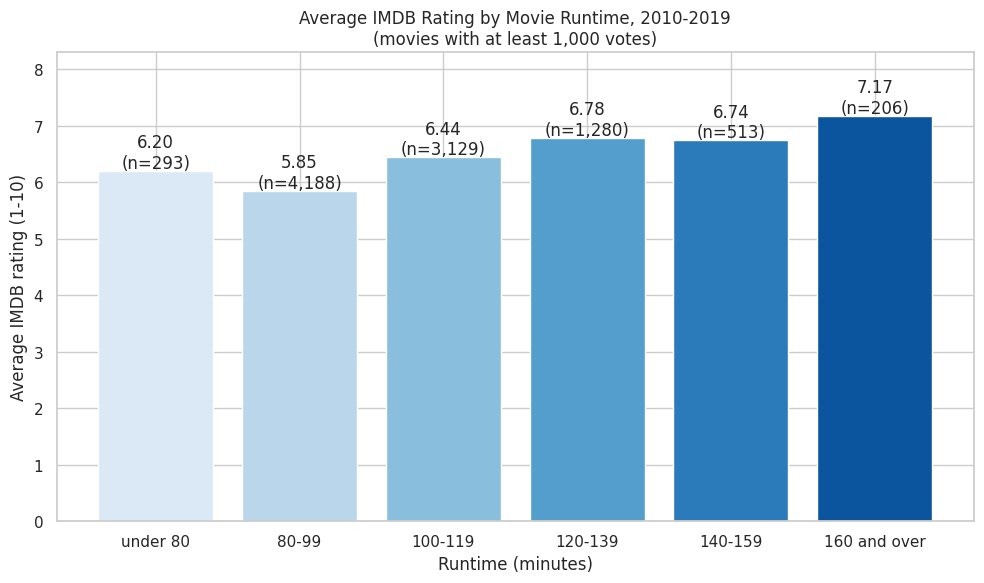

In [19]:
# Visual supporting the business question: average rating by runtime band
import os
os.makedirs('images', exist_ok=True)
fig, ax = plt.subplots(figsize=(10, 6))
labels = runtime_df['runtime_band'].str[3:]
bars = ax.bar(labels, runtime_df['avg_rating'], color=sns.color_palette('Blues', len(runtime_df)))
for bar, v, n in zip(bars, runtime_df['avg_rating'], runtime_df['movies']):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 0.05, f"{v:.2f}\n(n={n:,})", ha='center')
ax.set_ylim(0, 8.3)
ax.set_title('Average IMDB Rating by Movie Runtime, 2010-2019\n(movies with at least 1,000 votes)')
ax.set_xlabel('Runtime (minutes)')
ax.set_ylabel('Average IMDB rating (1-10)')
plt.tight_layout()
plt.savefig('images/rating_by_runtime.png', dpi=150, bbox_inches='tight')
plt.show()

In [20]:
# Does the runtime pattern hold inside the biggest genres? (runtime band x genre, >= 30 movies per cell)
big = movies_df.assign(genre=movies_df['genres'].str.split(',')).explode('genre')
big = big[big['genre'].isin(['Drama', 'Comedy', 'Action', 'Thriller', 'Horror'])].copy()
big['runtime_band'] = pd.cut(big['runtime_minutes'], [0, 100, 120, 1000], labels=['under 100', '100-119', '120+'])
pivot = big.pivot_table(index='genre', columns='runtime_band', values='averagerating',
                        aggfunc=['mean', 'size'], observed=True).round(2)
pivot

mean                    size              
runtime_band under 100 100-119  120+ under 100 100-119  120+
genre                                                       
Action            5.34    6.28  6.58       780     560   658
Comedy            5.87    6.32  6.58      1633     899   466
Drama             6.15    6.56  6.92      2018    1837  1190
Horror            5.06    5.90  6.34      1007     244    64
Thriller          5.40    6.29  6.81       982     491   324

### Part 2 Summary: Initial Exploration Findings
- **Scope:** 145,081 movies were released 2010-2019 (the table also has titles with start years from 2020 up to 2115, which were excluded). Only 73,856 (about half) have a rating, and 45,103 of those rest on fewer than 100 votes, so a minimum vote threshold is needed. Of the 65,720 rated movies that also have runtime and genre, only 9,607 have at least 1,000 votes.
- **Genre:** Among genres with at least 100 well-voted movies, Documentary (7.27), Biography (6.96), Sport (6.93) and History (6.89) rate highest; Horror (5.28), Sci-Fi (5.71) and Thriller (5.90) rate lowest. Drama (5,045 movies) and Comedy (2,998) are the largest groups.
- **Runtime:** Average rating rises with length: 80-99 minutes averages 5.85, 100-119 min 6.44, 120-139 min 6.78 and 160+ min 7.17. Longer movies also attract many more votes (about 13,000 per movie at 80-99 min vs about 48,000 at 120-139 min). The very shortest band (under 80 min, only 293 movies) is a mild exception at 6.20.
- **Trend over time:** Average rating edged up from 6.26 (2010) to 6.42 (2018); 2019 is 6.70 but is based on only 2,180 rated movies, so it is less reliable.
- **Within genre:** In the pivot table, rating rises with runtime in all five big genres (e.g. Thriller 5.40 -> 6.29 -> 6.81, Drama 6.15 -> 6.56 -> 6.92), so the runtime effect is not just explained by genre mix. Cells with small samples (e.g. Horror 120+ min, n=64) should be read cautiously.

### Business Question
**For a studio deciding which films to greenlight, which combination of genre and runtime delivers the highest audience ratings among films with an established audience (1,000+ votes), and does the "longer movies score higher" pattern hold inside each genre or is it explained by genre mix?**
This stems from the exploration: runtime and genre both strongly relate to rating, but long films are also more often dramas, biographies and documentaries, so we need to separate the two effects before recommending a target runtime. The pivot table above is a first look; a deeper analysis would add votes (popularity) as a second success measure, because high ratings on small audiences may not be commercially attractive.

### Potential Data Cleaning Tasks
1. **Filter invalid years:** remove movies with start_year after 2019 (values go up to 2115) and any null start_year.
2. **Null handling:** exclude (not fill) rows with null runtime_minutes (about 21% of movies), null genres (about 4%), and movies with no row in movie_ratings (about half).
3. **Split multi-valued genres:** `genres` stores several genres in one comma-separated string; it needs to be split into one row per movie-genre (or a separate genre table).
4. **Runtime outliers:** runtimes range from 1 to 51,420 minutes; set sensible bounds (e.g., remove under 40 or over 300 minutes, and review 48 titles over 600 minutes).
5. **Low-vote ratings:** set a minimum number of votes (this analysis uses 1,000) so ratings are not driven by a handful of users.
6. **Duplicates/inconsistent titles:** about 1,870 title+year pairs appear more than once in movie_basics (across all years), and 14,456 movies in 2010-2019 have an original_title different from primary_title; standardize text (case, whitespace) and de-duplicate before joining on titles.
7. **Data types:** confirm start_year and runtime_minutes are numeric and standardize categorical text (genres) in consistent case.
8. **Join key checks:** confirm movie_id is unique in movie_basics and movie_ratings before joining (it is here), and that principals/directors/writers link correctly to persons.

In [21]:
# Close the second connection
conn4.close()